# Explainable Hybrid Feature Selection for IDS - CIC-IDS 2017 (second dataset of the paper)
Same pipeline as the IoMT notebook: Pearson filter -> Feature Importance (A) + SHAP (B) -> HFS = (A ∩ B) + 95%·(A − B) -> RF / LightGBM -> SHAP + LIME.

**Kaggle setup (once):** *Add Data* -> search "CIC-IDS2017" and add the version that has the 8 `...pcap_ISCX.csv` files (MachineLearningCSV, 78 features + Label) -> *Settings -> Internet ON* (only for `pip install lime`). Run All.

In [14]:
!pip -q install lime

In [15]:
import os, glob, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')

# ---------------- CONFIG (change here only) ----------------
SEED          = 42
INPUT_DIR     = '/kaggle/input'
OUT_DIR       = '/kaggle/working'
N_PER_CLASS   = 50_000    # paper: balanced subset of 100,000 = 50k benign + 50k attack
TEST_SIZE     = 0.30      # paper: 70/30 split
PEARSON_THR   = 0.90      # paper: |r| > 0.9
THR_MULT      = 1.0       # selection threshold = THR_MULT * mean importance (tune to get 12 / 8 features)
HFS_FRAC      = 0.95      # paper: 95 %
SHAP_N        = 2000      # rows used to compute SHAP values
CLASSIFIERS   = ['RF', 'LGBM']
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Find the CIC-IDS 2017 CSV files on Kaggle

In [16]:
all_csvs = sorted(glob.glob(f'{INPUT_DIR}/**/*.csv', recursive=True))
print(len(all_csvs), 'csv files found')
for f in all_csvs[:80]:
    print(f'{os.path.getsize(f)/1e6:10.1f} MB  {f}')

def header_names(f):
    try:
        return [c.strip().lower() for c in pd.read_csv(f, nrows=0, encoding='latin1').columns]
    except Exception:
        return []

def is_ids_csv(f):
    h = set(header_names(f))
    return 'flow duration' in h and bool({'destination port', 'dst port'} & h)   # label column is detected in Section 2

FILES = [f for f in all_csvs if is_ids_csv(f)]
# If the Kaggle dataset has several versions (folders) of the same data, use only ONE folder (avoid double counting)
folders = sorted({os.path.dirname(f) for f in FILES})
if len(folders) > 1:
    pick = [d for d in folders if 'machinelearning' in d.lower()] or folders[:1]
    FILES = [f for f in FILES if os.path.dirname(f) == pick[0]]
    print('\nMultiple folders found, using only:', pick[0])
# Or set FILES manually, e.g. FILES = ['/kaggle/input/xyz/Monday-WorkingHours.pcap_ISCX.csv', ...]

if not FILES:
    print('\nNO CIC-IDS2017 file recognised. First columns of the first csv files:')
    for f in all_csvs[:3]:
        print(' ', os.path.basename(f), '->', header_names(f)[:10])
    raise FileNotFoundError('No CIC-IDS2017 csv found: add the dataset (Add Data) or set FILES manually; see the printout above.')

print('\nUsing', len(FILES), 'CIC-IDS2017 files (paper uses the full set, 8 files):')
for f in FILES: print('  ', f)

8 csv files found
      77.1 MB  /kaggle/input/datasets/chethuhn/network-intrusion-dataset/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
      76.9 MB  /kaggle/input/datasets/chethuhn/network-intrusion-dataset/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
      58.3 MB  /kaggle/input/datasets/chethuhn/network-intrusion-dataset/Friday-WorkingHours-Morning.pcap_ISCX.csv
     176.9 MB  /kaggle/input/datasets/chethuhn/network-intrusion-dataset/Monday-WorkingHours.pcap_ISCX.csv
      83.1 MB  /kaggle/input/datasets/chethuhn/network-intrusion-dataset/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
      52.0 MB  /kaggle/input/datasets/chethuhn/network-intrusion-dataset/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
     135.1 MB  /kaggle/input/datasets/chethuhn/network-intrusion-dataset/Tuesday-WorkingHours.pcap_ISCX.csv
     225.2 MB  /kaggle/input/datasets/chethuhn/network-intrusion-dataset/Wednesday-workingHours.pcap_ISCX.csv

Using 8 CIC-IDS2017 files (paper

## 2. Load + merge all files (labels contain a non-UTF8 character, so encoding='latin1')

In [17]:
NON_FEATURES = {'Flow ID', 'Source IP', 'Src IP', 'Source Port', 'Src Port', 'Destination IP', 'Dst IP', 'Timestamp', 'SimillarHTTP', 'Unnamed: 0'}
LABEL_CANDIDATES = ['label', 'attack type', 'attack_type', 'attack category', 'attack', 'class']

def find_label_col(cols):
    for cand in LABEL_CANDIDATES:
        for c in cols:
            if c.strip().lower() == cand:
                return c
    return cols[-1]                                         # fallback: last column

dfs = []
for f in FILES:
    cols = list(pd.read_csv(f, nrows=0, encoding='latin1').columns)
    use = [c for c in cols if c.strip() not in NON_FEATURES]
    lab = find_label_col(use)
    dtypes = {c: np.float32 for c in use if c != lab}
    d = pd.read_csv(f, usecols=use, dtype=dtypes, encoding='latin1')
    d.columns = d.columns.str.strip()                       # raw headers can have leading spaces
    d = d.rename(columns={lab.strip(): 'Label'})
    dfs.append(d)
    print(os.path.basename(f), d.shape, '| label column used:', repr(lab.strip()))
df = pd.concat(dfs, ignore_index=True); del dfs
print('\nRaw merged:', df.shape, '(paper: ~2,830,540 samples, 79 columns incl. label)')
print(df['Label'].value_counts())

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (225745, 79) | label column used: 'Label'
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (286467, 79) | label column used: 'Label'
Friday-WorkingHours-Morning.pcap_ISCX.csv (191033, 79) | label column used: 'Label'
Monday-WorkingHours.pcap_ISCX.csv (529918, 79) | label column used: 'Label'
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (288602, 79) | label column used: 'Label'
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (170366, 79) | label column used: 'Label'
Tuesday-WorkingHours.pcap_ISCX.csv (445909, 79) | label column used: 'Label'
Wednesday-workingHours.pcap_ISCX.csv (692703, 79) | label column used: 'Label'

Raw merged: (2830743, 79) (paper: ~2,830,540 samples, 79 columns incl. label)
Label
BENIGN                          2273097
DoS Hulk                         231073
PortScan                         158930
DDoS                             128027
DoS GoldenEye                     10293
FTP-Patator   

## 3. Cleaning (as in the paper), balanced 100k subset, 70/30 split, Min-Max scaling
Paper steps for CIC-IDS2017: handle missing/infinite values -> remove redundant attributes (-> 70 features) -> remove duplicates -> balanced subset (50,000 benign + 50,000 attack) -> 70/30 split -> Min-Max scaling (fit on train only).
Here "redundant attributes" = constant (zero-variance) columns: 78 − 8 = 70 features, which matches the paper.

In [18]:
FEATS = [c for c in df.columns if c != 'Label']
df[FEATS] = df[FEATS].replace([np.inf, -np.inf], np.nan)
n0 = len(df)
df = df.dropna().reset_index(drop=True)                    # missing / infinite rows removed
print(f'Rows with NaN/inf removed: {n0 - len(df)}')

const = [c for c in FEATS if df[c].min() == df[c].max()]    # redundant (constant) attributes
df = df.drop(columns=const)
FEATS = [c for c in df.columns if c != 'Label']
print(f'Constant columns removed: {len(const)} -> {const}')
print(f'Features now: {len(FEATS)}   (paper: 70; if far fewer, this Kaggle version was already cleaned/reduced - mention it in the presentation)')

n1 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplicate rows removed: {n1 - len(df)} -> {len(df)} rows left')

df['is_attack'] = (~df['Label'].astype(str).str.contains('benign|normal', case=False)).astype(np.int8)
if df['is_attack'].nunique() < 2:
    print(df['Label'].value_counts())
    raise ValueError("Could not separate benign from attack using the Label column (see counts above). Change 'benign|normal' to the benign class name.")
print(df['is_attack'].value_counts().rename({0: 'benign', 1: 'attack'}))

benign, attack = df[df.is_attack == 0], df[df.is_attack == 1]
n = min(N_PER_CLASS, len(benign), len(attack))
data = (pd.concat([benign.sample(n, random_state=SEED), attack.sample(n, random_state=SEED)])
          .sample(frac=1, random_state=SEED).reset_index(drop=True))
del df, benign, attack

y = data['is_attack'].values
X = data[FEATS]
print('\nBalanced subset:', X.shape)

Xtr_raw, Xte_raw, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
scaler = MinMaxScaler().fit(Xtr_raw)

def prep(Xr):
    return pd.DataFrame(scaler.transform(Xr), columns=FEATS).astype(np.float32)

Xtr, Xte = prep(Xtr_raw), prep(Xte_raw)
del data, X, Xtr_raw, Xte_raw
print('train:', Xtr.shape, ' test:', Xte.shape, ' attack share in test: %.3f' % yte.mean())

Rows with NaN/inf removed: 2867
Constant columns removed: 8 -> ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Features now: 70   (paper: 70; if far fewer, this Kaggle version was already cleaned/reduced - mention it in the presentation)
Duplicate rows removed: 329896 -> 2497980 rows left
is_attack
benign    2072254
attack     425726
Name: count, dtype: int64

Balanced subset: (100000, 70)
train: (70000, 70)  test: (30000, 70)  attack share in test: 0.500


## 4. Pearson correlation filter (|r| > 0.9, computed on train only)

In [19]:
def pearson_filter(Xtrain, thr=0.9):
    corr  = Xtrain.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    drop  = [c for c in upper.columns if (upper[c] > thr).any()]
    return [c for c in Xtrain.columns if c not in drop], drop

ALL_COLS = list(Xtr.columns)
PEARSON_COLS, DROPPED = pearson_filter(Xtr, PEARSON_THR)
print(f'Before Pearson: {len(ALL_COLS)} features | After: {len(PEARSON_COLS)} | Dropped {len(DROPPED)}:')
print(DROPPED)

Before Pearson: 70 features | After: 39 | Dropped 31:
['Total Backward Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Std', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow IAT Max', 'Fwd IAT Total', 'Fwd IAT Std', 'Fwd IAT Max', 'Bwd IAT Max', 'Fwd Packets/s', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count', 'ECE Flag Count', 'Average Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Active Min', 'Idle Mean', 'Idle Max', 'Idle Min']


## 5. Hybrid Feature Selection: A = Feature Importance, B = SHAP, HFS = (A ∩ B) + 95%·(A − B)

In [20]:
def make_model(kind):
    if kind == 'RF':
        return RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
    return LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1)   # standard configuration

def evaluate(m, Xt, yt):
    p, pr = m.predict(Xt), m.predict_proba(Xt)[:, 1]
    return dict(Accuracy=accuracy_score(yt, p), Precision=precision_score(yt, p),
                Recall=recall_score(yt, p), F1=f1_score(yt, p), AUC=roc_auc_score(yt, pr))

def class1(sv):
    """SHAP output -> (n_samples, n_features) for the 'attack' class (works for old and new shap versions)."""
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[:, :, 1]
    return sv

def select_by_score(score, mult=THR_MULT):
    s = score.sort_values(ascending=False)
    keep = s[s >= s.mean() * mult].index.tolist()
    return keep if keep else [s.index[0]]

def fi_select(model, cols):                      # set A (ranked by importance)
    fi = pd.Series(model.feature_importances_, index=cols)
    return select_by_score(fi), fi

def shap_select(model, Xdf):                     # set B (ranked by mean |SHAP|)
    sample = Xdf.sample(min(SHAP_N, len(Xdf)), random_state=SEED)
    sv = class1(shap.TreeExplainer(model).shap_values(sample))
    sh = pd.Series(np.abs(sv).mean(axis=0), index=Xdf.columns)
    return select_by_score(sh), sh

def hybrid(A, B, frac=HFS_FRAC):
    inter = [f for f in A if f in B]             # A ∩ B  (agreement)
    diff  = [f for f in A if f not in B]         # A − B  (already ranked by FI)
    k     = int(np.floor(frac * len(diff)))      # top 95 % of A − B
    H = inter + diff[:k]
    return H if H else A

## 6. Run all experiments (RF / LightGBM × with / without Pearson × Baseline, +SHAP, +FI, Hybrid)

In [21]:
store, rows = {}, []
t0 = time.time()
for clf in CLASSIFIERS:
    for use_p in [False, True]:
        cols = PEARSON_COLS if use_p else ALL_COLS
        base = make_model(clf).fit(Xtr[cols], ytr)
        A, fi = fi_select(base, cols)
        B, sh = shap_select(base, Xtr[cols])
        H = hybrid(A, B)
        sets = {'Baseline': cols, '+ SHAP': B, '+ FI': A, 'Hybrid': H}
        models = {'Baseline': base}
        for name in ['+ SHAP', '+ FI', 'Hybrid']:
            models[name] = make_model(clf).fit(Xtr[sets[name]], ytr)
        for name, m in models.items():
            rows.append(dict(Model=clf, Pearson='With' if use_p else 'Without', Variant=name,
                             n_features=len(sets[name]), **evaluate(m, Xte[sets[name]], yte)))
        store[(clf, use_p)] = dict(sets=sets, models=models, fi=fi, shap=sh)
        print(f'{clf:5s} Pearson={use_p!s:5s} |A|={len(A):2d} |B|={len(B):2d} |A∩B|={len([f for f in A if f in B]):2d} '
              f'|HFS|={len(H):2d}   [{time.time()-t0:.0f}s]')
results = pd.DataFrame(rows)

RF    Pearson=False |A|=22 |B|=20 |A∩B|=20 |HFS|=21   [96s]
RF    Pearson=True  |A|=16 |B|=15 |A∩B|=15 |HFS|=15   [174s]
LGBM  Pearson=False |A|=18 |B|=10 |A∩B|= 8 |HFS|=17   [179s]
LGBM  Pearson=True  |A|=13 |B|= 5 |A∩B|= 4 |HFS|=12   [183s]


## 7. Results table (compare with the paper's Table I and II)

In [22]:
PAPER_ACC = {
 ('RF','Without'):   {'Baseline':.998,'+ SHAP':.988,'+ FI':.984,'Hybrid':.998},
 ('RF','With'):      {'Baseline':.997,'+ SHAP':.985,'+ FI':.999,'Hybrid':.999},
 ('LGBM','Without'): {'Baseline':.998,'+ SHAP':.994,'+ FI':.999,'Hybrid':.999},
 ('LGBM','With'):    {'Baseline':.997,'+ SHAP':.988,'+ FI':.999,'Hybrid':.997},
}
results['Paper_Accuracy'] = [PAPER_ACC[(r.Model, r.Pearson)][r.Variant] for r in results.itertuples()]
results['Variant'] = results.apply(lambda r: r.Variant.replace('Baseline', r.Model) if r.Variant == 'Baseline' else f"{r.Model} {r.Variant}", axis=1)
show = results.round(4)
display(show)
show.to_csv(f'{OUT_DIR}/results_ids2017.csv', index=False)

print('\nTable V analogue - features kept by Hybrid (with Pearson); paper: Hybrid RF 12, Hybrid LGBM 8:')
for clf in CLASSIFIERS:
    print(f"  Hybrid {clf}: {len(store[(clf, True)]['sets']['Hybrid'])} features ->", store[(clf, True)]['sets']['Hybrid'])

,Model,Pearson,Variant,n_features,Accuracy,Precision,Recall,F1,AUC,Paper_Accuracy
0,RF,Without,RF,70,0.9982,0.9987,0.9977,0.9982,0.9998,0.998
1,RF,Without,RF + SHAP,20,0.9975,0.9961,0.9989,0.9975,0.9999,0.988
2,RF,Without,RF + FI,22,0.9976,0.9962,0.9989,0.9976,0.9998,0.984
3,RF,Without,RF Hybrid,21,0.9976,0.9963,0.9989,0.9976,0.9999,0.998
4,RF,With,RF,39,0.9987,0.9989,0.9985,0.9987,0.9998,0.997
5,RF,With,RF + SHAP,15,0.9986,0.9987,0.9985,0.9986,0.9999,0.985
6,RF,With,RF + FI,16,0.9985,0.9983,0.9987,0.9985,0.9998,0.999
7,RF,With,RF Hybrid,15,0.9986,0.9984,0.9987,0.9986,0.9998,0.999
8,LGBM,Without,LGBM,70,0.9991,0.9988,0.9995,0.9991,1.0000,0.998
9,LGBM,Without,LGBM + SHAP,10,0.9974,0.9957,0.9992,0.9974,0.9999,0.994



Table V analogue - features kept by Hybrid (with Pearson); paper: Hybrid RF 12, Hybrid LGBM 8:
  Hybrid RF: 15 features -> ['Destination Port', 'Bwd Packet Length Max', 'Init_Win_bytes_backward', 'Init_Win_bytes_forward', 'Min Packet Length', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Bwd Packet Length Min', 'Flow IAT Mean', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Total Fwd Packets', 'Flow Packets/s', 'PSH Flag Count', 'Flow IAT Std']
  Hybrid LGBM: 12 features -> ['Destination Port', 'Init_Win_bytes_forward', 'Init_Win_bytes_backward', 'Bwd Packet Length Max', 'Fwd IAT Min', 'Flow IAT Min', 'Total Length of Fwd Packets', 'Total Fwd Packets', 'Fwd IAT Mean', 'Flow IAT Std', 'Flow Bytes/s', 'Flow Duration']


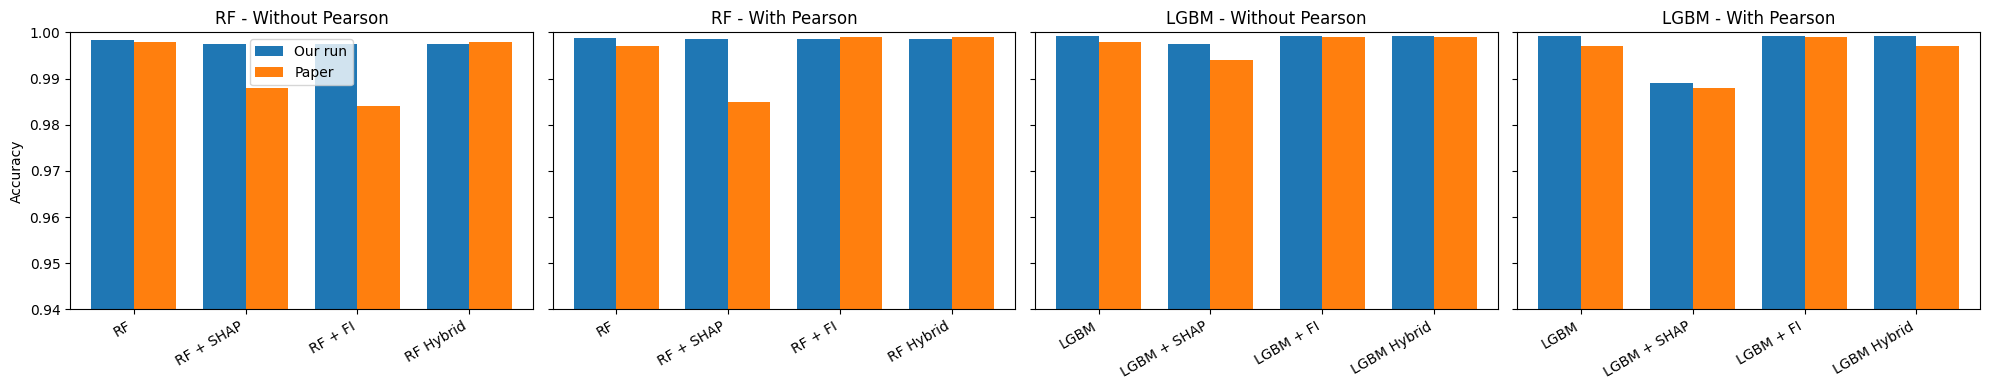

In [23]:
fig, axes = plt.subplots(1, len(CLASSIFIERS) * 2, figsize=(5 * len(CLASSIFIERS) * 2, 4), sharey=True)
k = 0
for clf in CLASSIFIERS:
    for pear in ['Without', 'With']:
        d = results[(results.Model == clf) & (results.Pearson == pear)]
        x = np.arange(len(d)); w = 0.38
        axes[k].bar(x - w/2, d.Accuracy, w, label='Our run')
        axes[k].bar(x + w/2, d.Paper_Accuracy, w, label='Paper')
        axes[k].set_xticks(x); axes[k].set_xticklabels(d.Variant, rotation=30, ha='right')
        axes[k].set_title(f'{clf} - {pear} Pearson'); axes[k].set_ylim(0.94, 1.0)
        k += 1
axes[0].set_ylabel('Accuracy'); axes[0].legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/ids2017_accuracy_vs_paper.png', dpi=150); plt.show()

## 8. Confusion matrices (Hybrid models, with Pearson)

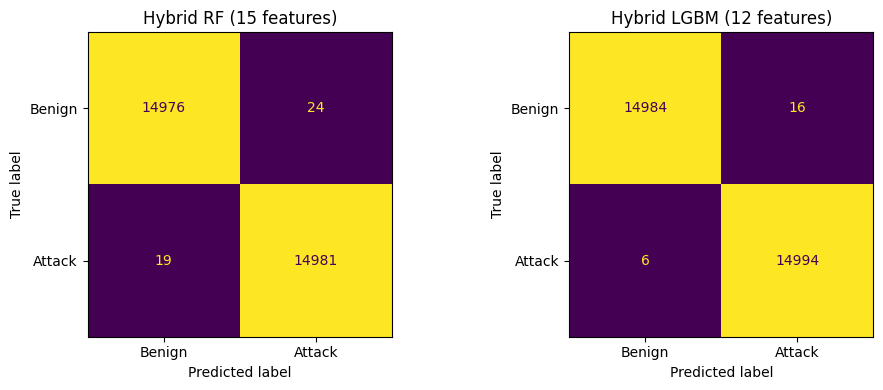

In [24]:
fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(5 * len(CLASSIFIERS), 4))
axes = np.atleast_1d(axes)
for ax, clf in zip(axes, CLASSIFIERS):
    s = store[(clf, True)]; feats = s['sets']['Hybrid']
    ConfusionMatrixDisplay.from_estimator(s['models']['Hybrid'], Xte[feats], yte,
                                          display_labels=['Benign', 'Attack'], ax=ax, colorbar=False)
    ax.set_title(f'Hybrid {clf} ({len(feats)} features)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/ids2017_confusion_matrices.png', dpi=150); plt.show()

## 9. SHAP global explanations (Fig. 8 / Fig. 9 of the paper)

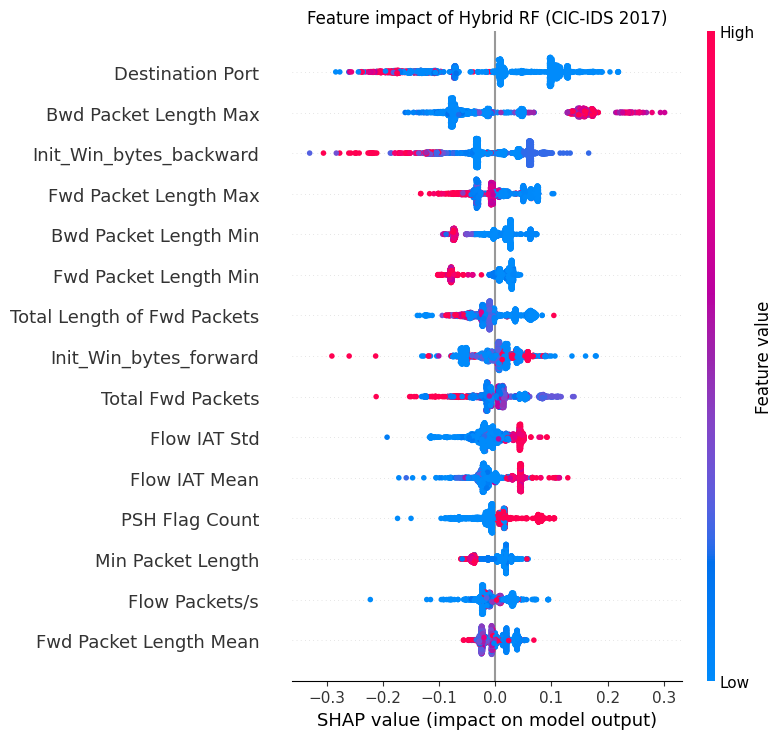

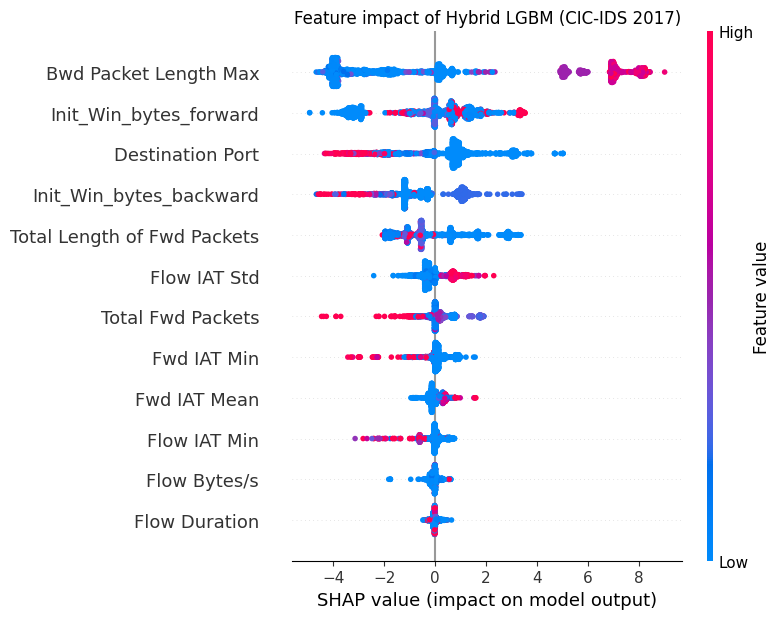

In [25]:
for clf in CLASSIFIERS:
    s = store[(clf, True)]; feats = s['sets']['Hybrid']
    sample = Xte[feats].sample(min(SHAP_N, len(Xte)), random_state=SEED)
    sv = class1(shap.TreeExplainer(s['models']['Hybrid']).shap_values(sample))
    plt.figure()
    shap.summary_plot(sv, sample, show=False)
    plt.title(f'Feature impact of Hybrid {clf} (CIC-IDS 2017)')
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/ids2017_shap_{clf}.png', dpi=150, bbox_inches='tight'); plt.show()

## 10. LIME local explanations (Tables VIII / IX of the paper)

.for clf in CLASSIFIERS:
    s = store[(clf, True)]; feats = s['sets']['Hybrid']; m = s['models']['Hybrid']
    pred = m.predict(Xte[feats])
    idx = int(np.where((pred == 1) & (yte == 1))[0][0])          # first correctly detected attack
    explainer = LimeTabularExplainer(Xtr[feats].values, feature_names=feats,
                                     class_names=['Benign', 'Attack'], mode='classification',
                                     discretize_continuous=True, random_state=SEED)
    exp = explainer.explain_instance(Xte[feats].values[idx],
                                     lambda a: m.predict_proba(pd.DataFrame(a, columns=feats)),
                                     num_features=min(5, len(feats)))
    print(f'\nLIME explanation - Hybrid {clf} (test sample #{idx}, predicted = Attack)')
    display(pd.DataFrame(exp.as_list(), columns=['Feature condition', 'LIME weight']).round(6))

## 11. Notes for the presentation
* Paper's CIC-IDS2017 accuracies are ~98-99.9 %, so results close to 99.x % are expected; exact decimals can differ (random seed, which duplicates/NaN rows were dropped).
* The paper's Fig. 8 / Fig. 9 highlight Destination Port, Packet Length Variance, Bwd Packet Length Max, Init_Win_bytes_backward: check whether the same features appear in your SHAP plots and LIME tables.
* To get closer to the paper's feature counts (12 for Hybrid RF, 8 for Hybrid LGBM), change `THR_MULT` (higher -> fewer features) and re-run from Section 6.
* Assumptions to state: constant columns = "redundant attributes", rows with NaN/inf dropped, mean-importance threshold for selecting A and B.